# Aprendiendo a caminar con PPO

ESTUDIANTES: `David Moya Castillo, Said Daniel Huarita Mollo`

![Bipedal Walker](https://albarji-labs-materials.s3.eu-west-1.amazonaws.com/bipedalWalker.png)

En esta práctica vamos a resolver el problema de optimizar un robot simulado para que sea capaz de caminar sobre un terreno de la forma más eficiente posible. Para ello utilizaremos el algoritmo Proximal Policy Optimization (PPO).

## Instrucciones

A lo largo del notebook encontrarás celdas que debes rellenar con tu propio código. Sigue las instrucciones del notebook y presta atención a los siguientes iconos:

<img src="https://albarji-labs-materials.s3-eu-west-1.amazonaws.com/question.png" height="80" width="80" style="float: right;"/>

***

<font color=#ad3e26>
Deberás resolver el ejercicio escribiendo tu propio código o respuesta en la celda inmediatamente inferior.
    <b>La nota máxima que puede obtenerse con esta clase de ejercicios es de 7 sobre 10.</b>
</font>

***

<img src="https://albarji-labs-materials.s3-eu-west-1.amazonaws.com/exclamation.png" height="80" width="80" style="float: right;"/>

***
<font color=#2655ad>
Esto es una pista u observación de utilidad que puede ayudarte a resolver el ejercicio. Presta atención a estas pistas para comprender el ejercicio en mayor profundidad.
</font>

***

<img src="https://albarji-labs-materials.s3-eu-west-1.amazonaws.com/pro.png" height="80" width="80" style="float: right;"/>

***
<font color=#259b4c>
Este es un ejercicio avanzado que te puede ayudar a profundizar en el tema, y a conseguir una calificación más alta. <b>Resolviendo esta clase de ejercicios puedes llegar conseguir hasta 3 puntos sobre 10.</b> ¡Buena suerte!</font>

***

## Preliminares

En primer lugar vamos a instalar las librerías necesarias para ejecutar PPO, así que como para correr el entorno de simulación.

Aquí se proporciona una función para generar vídeos de las ejecuciones del agente

In [ ]:
# Entrenamiento
from stable_baselines3 import PPO
from functools import partial
from stable_baselines3.common.vec_env import VecVideoRecorder, DummyVecEnv
import gymnasium as gym
from stable_baselines3.common.env_util import make_vec_env

# Evaluación
from stable_baselines3.common.evaluation import evaluate_policy

def record_video(env, model, name_prefix, steps=2000):
    video_folder = "videos/"

    if callable(env):
        envfun = partial(env, render_mode="rgb_array")
    else:
        envfun = lambda: gym.make(env, render_mode="rgb_array")

    vec_env = DummyVecEnv([envfun])
    obs = vec_env.reset()

    vec_env = VecVideoRecorder(vec_env, video_folder,
                               record_video_trigger=lambda x: x == 0, video_length=steps,
                               name_prefix=name_prefix)

    obs = vec_env.reset()
    total_reward = 0

    for _ in range(steps + 1):
        #action = [model.predict(obs[0])[0]]
        action,_ = model.predict(obs,deterministic=True)
        obs, rewards, dones, infos = vec_env.step(action)
        total_reward += rewards[0]

        if dones[0]:
            break

    vec_env.close()
    print("Total reward of the episode:", total_reward)

## Enseñando a un robot a andar

El entorno sobre el que vamos a trabajar es [Bipedal Walker](https://gymnasium.farama.org/environments/box2d/bipedal_walker/) (v3). En él, un robot simulado debe atravesar un terreno irregular de la forma más eficiente posible. Como observaciones, el robot dispone de:
- Módulo de la velocidad de la cabeza.
- Vector de velocidad angular.
- Componente de velocidad horizontal.
- Componente de velocidad vertical.
- Posición de las juntas.
- Módulo de la velocidad angular de las juntas.
- Contacto de las piernas con el suelo.
- 10 mediciones de distancia simulando un LIDAR.

El robot tiene permitidas 4 acciones continuas, en el rango `[-1, 1]`, que representan la velocidad del motor que aplicamos en las 4 juntas disponibles: dos en la "cintura" y dos en las "rodillas" del robot.

Se obtiene recompensa a medida que el robot se mueve hacia la derecha. Si la cabeza del robot robot toca el suelo, sufre una penalización de `-100` puntos y el episodio termina. Aplicar fuerza a los motores supone una pequeña penalización, por lo que un robot más eficiente conseguirá más recompensa al desplazarse. El episodio termina sin penalización si el robot alcanza el final del recorrido.

<img src="https://albarji-labs-materials.s3-eu-west-1.amazonaws.com/question.png" height="80" width="80" style="float: right;"/>

***

<font color=#ad3e26>
Entrena un agente usando <a href=https://stable-baselines3.readthedocs.io/en/master/modules/ppo.html>PPO</a> que consiga al menos 200 puntos de recompensa en promedio en una evaluación de 100 episodios.

Deberás entregar tanto este notebook con la solución, como un vídeo que muestre al agente corriendo.
</font>

***

<img src="https://albarji-labs-materials.s3-eu-west-1.amazonaws.com/exclamation.png" height="80" width="80" style="float: right;"/>

***
<font color=#2655ad>
Algunos consejos para lograr esto:
    <ul>
        <li>No necesitas usar GPU para resolver esta práctica. El entorno es lo suficientemente sencillo como para ejecutar rápidamente en CPU.</li>
        <li>Comienza con entrenamientos de 100.000 timesteps, y ve probando a modificar diferentes parámetros de PPO y de la construcción del entorno para observar con cuáles consigues obtener mejor reward al final del entrenamiento.</li>
        <li>El primer parámetro a optimizar debería ser el número de entornos vectorizados, ya que esto te permite entrenar más rápido. Ten en cuenta que PPO realiza un paso de aprendizaje cada vez que recoge <it>n_steps * n_envs</it> muestras, por lo que si se aumenta el número de entornos se realizarán menos pasos de aprendizaje. Para mantener un buen ritmo de aprendizaje se recomienda ajustar el parámetro <it>n_steps</it> según el número de entornos, por ejemplo a <it>n_steps=2048//n_envs</it>.
        <li>La arquitectura de la red neuronal también es un parámetro relevante a optimizar. Prueba modificando el número de capas y el número de neuronas por capa, empezando de menos a más.</li>
        <li>El factor de entropía de PPO (<it>ent_coef</it>), que gobierna su cantidad de exploración, también puede aportar mejoras si se ajusta adecuadamente. Se recomienda empezar por valores muy pequeños (ej. 1e-4) e ir subiendo en múltiplos de 10.</li>
        <li>Una vez optimizados todos estos parámetros puedes probar a aumentar el número de timesteps de entrenamiento y ver si alcanzas la recompensa objetivo en evaluación.</li>
    </ul>
</font>

***

<img src="https://albarji-labs-materials.s3-eu-west-1.amazonaws.com/pro.png" height="80" width="80" style="float: right;"/>

***
<font color=#259b4c>
Se considera que este entorno ha sido completamente resuelto si eres capaz de obtener 300 puntos de recompensa. ¿Puedes crear un agente que lo consiga?
</font>

***

### 1. Agente básico.

Se entrena un primer agente PPO sin ningún tipo de ajuste sobre la arquitectura de la
red neuronal ni sobre los parámetros de exploración, con el objetivo de establecer una
línea base de referencia sobre la que mejorar en experimentos posteriores.

Se utiliza un único entorno de simulación (`n_envs=1`) y una arquitectura de red neuronal
de dos capas ocultas de 64 neuronas cada una, que es la que aplica `MlpPolicy`
cuando no se especifica ninguna configuración mediante `policy_kwargs`. Los parámetros principales son:

- `learning_rate=3e-4`: tasa de aprendizaje del optimizador. Controla el tamaño de cada paso al ajustar los pesos de la red neuronal.
- `n_steps=2048`: número de pasos que recoge el agente en el entorno antes de realizar una actualización de la red. Con un único entorno, cada actualización consume 2048 experiencias consecutivas.
- `batch_size=64`: tamaño del mini-lote usado en cada paso de gradiente. Las 2048 experiencias se dividen en lotes de 64 para actualizar la red de forma iterativa.
- `n_epochs=10`: número de veces que se reutilizan las experiencias recogidas en cada ronda de aprendizaje antes de descartarlas.
- `gamma=0.99`: factor de descuento. Determina cuánto se valoran las recompensas futuras frente a las inmediatas. Un valor cercano a 1 implica que el agente planifica a largo plazo.
- `gae_lambda=0.95`: parámetro de la Estimación Generalizada de Ventaja (GAE). Controla el equilibrio entre sesgo y varianza al estimar cuán buena fue una acción respecto a lo esperado.
- `clip_range=0.2`: rango de recorte del ratio de probabilidades entre la política nueva y la anterior. Limita cuánto puede cambiar la política en cada actualización, garantizando la estabilidad del entrenamiento.
- `ent_coef=0.0`: coeficiente de entropía. Con valor 0, no se aplica ningún incentivo adicional a la exploración; el agente explota únicamente lo que ya conoce.
- `total_timesteps=100_000`: número total de pasos de interacción con el entorno durante el entrenamiento.

In [ ]:
# Se crea el entorno
env = make_vec_env("BipedalWalker-v3", n_envs=1)

print('Training PPO agent on BipedalWalker-v3...')

# Crea el modelo PPO
model = PPO(
    policy="MlpPolicy",
    env=env,
    learning_rate=3e-4,
    n_steps=2048,
    batch_size=64,
    n_epochs=10,
    gamma=0.99,
    gae_lambda=0.95,
    clip_range=0.2,
    ent_coef=0.0,
    tensorboard_log="./ppo_bipedal_tensorboard/"
)

# Entrenamiento
model.learn(total_timesteps=100_000)

# Guarda el modelo
model.save("ppo_bipedalwalker_01_basico")

print('Training completed!')

# Evalua el modelo entreanado
print('Evaluating the trained model over 100 episodes...')
mean_reward, std_reward  = evaluate_policy(model, env, n_eval_episodes=100)
print(f"Mean reward: {mean_reward:.2f} +/- {std_reward:.2f}")

# Se cierra el entorno
env.close()
print('Evaluation completed!')

Training PPO agent on BipedalWalker-v3...
Training completed!
Evaluating the trained model over 100 episodes...
Mean reward: 189.41 +/- 95.68
Evaluation completed!


Evaluamos en un entorno diferente al de entrenamiento.

In [ ]:
eval_env = make_vec_env("BipedalWalker-v3", n_envs=1)
# Evalua el modelo entrenado
model = PPO.load("ppo_bipedalwalker_01_basico")
print('Evaluating the trained model over 100 episodes...')
mean_reward, std_reward  = evaluate_policy(model, eval_env, n_eval_episodes=100)
print(f"Mean reward: {mean_reward:.2f} +/- {std_reward:.2f}")

# Se cierra el entorno
eval_env.close()
print('Evaluation completed!')

Evaluating the trained model over 100 episodes...
Mean reward: 213.48 +/- 78.10


Grabamos video.

In [ ]:
record_video('BipedalWalker-v3', model, name_prefix='01_agente_basico',steps=2000)

MoviePy - Building video videos\01_1_agente_basico-step-0-to-step-2000.mp4.
MoviePy - Writing video videos\01_1_agente_basico-step-0-to-step-2000.mp4



MoviePy - Done !
MoviePy - video ready videos\01_1_agente_basico-step-0-to-step-2000.mp4
Total reward of the episode: 302.2832



#### Resultados del agente básico

| Evaluación | Mean reward | Std |
|---|---|---|
| Entorno de entrenamiento | 189.41 | ±95.68 |
| Entorno independiente | 213.48 | ±78.10 |

El agente consigue una recompensa media cercana al umbral de 200 puntos, lo que indica que ha aprendido a caminar en términos generales. Sin embargo, la desviación estándar es muy elevada (±95.68 en entrenamiento, ±78.10 en evaluación independiente), lo que revela un comportamiento muy inestable: en algunos episodios el robot camina bien, mientras que en otros cae rápidamente y acumula la penalización de -100 puntos.

Esta inestabilidad sugiere que el agente no ha consolidado una estrategia de marcha robusta, sino que puede depender en gran medida de las condiciones iniciales de cada episodio.
En los experimentos siguientes se abordará esta variabilidad mediante tres ajustes: el aumento del número de entornos vectorizados, la modificación de la arquitectura de la red neuronal y el incremento del número de timesteps de entrenamiento.

### 2. Agente Medio

Respecto al agente básico, se introducen dos cambios. El primero es el uso de
entornos vectorizados: en lugar de un único entorno, se ejecutan 4 en paralelo
(`n_envs=4`), lo que permite recoger experiencias de forma simultánea y acelerar
el entrenamiento. Para mantener el mismo ritmo de aprendizaje, se ajusta `n_steps` proporcionalmente: `n_steps = 2048 // n_envs = 512`, de forma que el número total de experiencias por actualización sigue siendo 2048.

El segundo cambio es la arquitectura de la red neuronal, que se especifica mediante el parámetro [`policy_kwargs`](https://stable-baselines3.readthedocs.io/en/master/guide/custom_policy.html#custom-network-architecture). Este parámetro permite personalizar la configuración interna de la política: en concreto, `net_arch` define el número de capas ocultas y el número de neuronas en cada una, tanto para el Actor (la red que decide qué acción tomar) como para el Critic (la red que estima cuán bueno es un estado).
En este caso se utilizan dos capas de 128 neuronas cada una (`net_arch=[128, 128]`), frente a las dos capas de 64 neuronas del agente básico, con el objetivo de dotar al agente de mayor capacidad para representar las relaciones entre las 24 observaciones del entorno y las 4 acciones continuas que debe producir.

El resto de parámetros se mantienen igual que en el agente básico.

In [ ]:
# Número de entornos en paralelo
n_envs = 4

# Crea entorno vectorizado
env = make_vec_env("BipedalWalker-v3", n_envs=n_envs)

# Define arquitectura del modelo
policy_kwargs = dict(net_arch=[128, 128])

print('Training PPO agent on BipedalWalker-v3...')

# Crea el modelo PPO
model = PPO(
    policy="MlpPolicy",
    env=env,
    policy_kwargs = policy_kwargs,
    learning_rate=3e-4,
    n_steps=2048 // n_envs,
    batch_size=64,
    n_epochs=10,
    gamma=0.99,
    gae_lambda=0.95,
    clip_range=0.2,
    ent_coef=0.0,
    tensorboard_log="./ppo_bipedal_tensorboard/"
)

# Entrenamiento
model.learn(total_timesteps=100_000)

# Se guarda el modelo
model.save("ppo_bipedalwalker_02_medio")

print('Training completed!')

# Evalua el modelo entrenado
print('Evaluating the trained model over 100 episodes...')
mean_reward, std_reward  = evaluate_policy(model, env, n_eval_episodes=100)
print(f"Mean reward: {mean_reward:.2f} +/- {std_reward:.2f}")

# Se cierra el entorno
env.close()
print('Evaluation completed!')

.venv\Lib\site-packages\pygame\pkgdata.py:25: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_stream, resource_exists


Training PPO agent on BipedalWalker-v3...
Training completed!
Evaluating the trained model over 100 episodes...
Mean reward: -46.12 +/- 73.91
Evaluation completed!


Evaluamos en un entorno diferente al de entrenamiento.

In [ ]:
eval_env = make_vec_env("BipedalWalker-v3", n_envs=1)
# Se evalua el modelo entrenado
model = PPO.load("ppo_bipedalwalker_02_medio")
print('Evaluating the trained model over 100 episodes...')
mean_reward, std_reward  = evaluate_policy(model, eval_env, n_eval_episodes=100)
print(f"Mean reward: {mean_reward:.2f} +/- {std_reward:.2f}")

# Se cierra el entorno
eval_env.close()
print('Evaluation completed!')

Evaluating the trained model over 100 episodes...
Mean reward: -48.76 +/- 70.83


Grabamos video.

In [ ]:
record_video('BipedalWalker-v3', model, name_prefix='02_agente_medio',steps=2000)

MoviePy - Building video videos\02_agente_medio-step-0-to-step-2000.mp4.
MoviePy - Writing video videos\02_agente_medio-step-0-to-step-2000.mp4



MoviePy - Done !
MoviePy - video ready videos\02_agente_medio-step-0-to-step-2000.mp4
Total reward of the episode: -95.23006


#### Resultados del agente medio

| Evaluación | Mean reward | Std |
|---|---|---|
| Entorno de entrenamiento | -46.12 | ±73.91 |
| Entorno independiente | -48.76 | ±70.83 |

Los resultados empeoran notablemente respecto al agente básico: la recompensa media cae a valores negativos, lo que indica que el robot cae con frecuencia y acumula la penalización de -100 puntos. La desviación estándar sigue siendo elevada, lo que confirma un comportamiento inconsistente.

La causa más probable es que el agente converge prematuramente a una estrategia
mediocre: sin ningún incentivo para explorar (`ent_coef=0.0`), la red más grande
encuentra rápidamente una solución subóptima (como quedarse quieto o caer de forma controlada) y deja de buscar alternativas mejores. En el experimento siguiente se introduce el coeficiente de entropía (`ent_coef`) para forzar al agente a explorar un mayor abanico de acciones durante el entrenamiento.

### 3. Agente Avanzado.

Respecto al agente medio, se introducen tres cambios orientados a corregir la
convergencia prematura observada anteriormente.

El primero es aumentar el número de entornos vectorizados de 4 a 8 (`n_envs=8`),
lo que permite recoger experiencias más diversas en cada ronda de aprendizaje y
acelerar el entrenamiento. El parámetro `n_steps` se ajusta de nuevo
proporcionalmente: `n_steps = 2048 // 8 = 256`.

El segundo cambio es la introducción del coeficiente de entropía (`ent_coef=1e-4`). Este parámetro añade un pequeño incentivo a la exploración durante el entrenamiento: penaliza a la política cuando se vuelve demasiado determinista, forzando al agente a seguir probando acciones variadas en lugar de quedarse atascado en estrategias mediocres. El valor `1e-4` es deliberadamente pequeño para no perjudicar la convergencia, siguiendo la recomendación de comenzar por valores bajos e ir subiendo si fuera necesario.

El tercer cambio es aumentar el número de timesteps de entrenamiento de 100.000
a 400.000, dando al agente suficiente tiempo para refinar la estrategia de marcha una vez que la exploración le permite descubrirla.

La arquitectura de la red neuronal se mantiene igual que en el agente medio:
dos capas de 128 neuronas (`net_arch=[128, 128]`).

In [ ]:
# Número de entornos en paralelo
n_envs = 8

# Se define la arquitectura
env = make_vec_env("BipedalWalker-v3", n_envs=n_envs)

# Define policy architecture,
policy_kwargs = dict(net_arch=[128, 128])

print('Training PPO agent on BipedalWalker-v3...')

# Se crea el modelo PPO
model = PPO(
    policy="MlpPolicy",
    env=env,
    policy_kwargs = policy_kwargs,
    learning_rate=3e-4,
    n_steps=2048 // n_envs,
    batch_size=64,
    n_epochs=10,
    gamma=0.99,
    gae_lambda=0.95,
    clip_range=0.2,
    ent_coef=1e-4,
    tensorboard_log="./ppo_bipedal_tensorboard/"
)

# Entrenamiento
model.learn(total_timesteps=400_000)

# Se guarda el modelo
model.save("ppo_bipedalwalker_03_avanzado")

print('Training completed!')

# Se evaluate el modelo entrenado
print('Evaluating the trained model over 100 episodes...')
mean_reward, std_reward  = evaluate_policy(model, env, n_eval_episodes=100)
print(f"Mean reward: {mean_reward:.2f} +/- {std_reward:.2f}")

# Se cierra el entorno
env.close()
print('Evaluation completed!')

Training PPO agent on BipedalWalker-v3...
Training completed!
Evaluating the trained model over 100 episodes...
Mean reward: 297.64 +/- 19.57
Evaluation completed!


Evaluamos en un entorno diferente al de entrenamiento.

In [ ]:
eval_env = make_vec_env("BipedalWalker-v3", n_envs=1)
model = PPO.load("ppo_bipedalwalker_03_avanzado")
# Evalua el modelo entrenado
print('Evaluating the trained model over 100 episodes...')
mean_reward, std_reward  = evaluate_policy(model, eval_env, n_eval_episodes=100)
print(f"Mean reward: {mean_reward:.2f} +/- {std_reward:.2f}")

# Se cierra el entorno
eval_env.close()
print('Evaluation completed!')

Evaluating the trained model over 100 episodes...
Mean reward: 300.50 +/- 1.04


Grabamos video

In [ ]:
record_video('BipedalWalker-v3', model, name_prefix='03_agente_avanzado',steps=2000)

MoviePy - Building video videos\02_agente_medio-step-0-to-step-2000.mp4.
MoviePy - Writing video videos\02_agente_medio-step-0-to-step-2000.mp4



MoviePy - Done !
MoviePy - video ready videos\02_agente_medio-step-0-to-step-2000.mp4
Total reward of the episode: 300.85626


#### Resultados del agente avanzado

| Evaluación | Mean reward | Std |
|---|---|---|
| Entorno de entrenamiento | 297.64 | ±19.57 |
| Entorno independiente | 300.50 | ±1.04 |

Los resultados mejoran de forma drástica respecto a los agentes anteriores. El agente supera el umbral de 300 puntos en el entorno independiente.

Especialmente destacable es la desviación estándar de ±1.04 en la evaluación
independiente: el agente se comporta de forma prácticamente idéntica en todos los episodios, lo que indica que ha consolidado una estrategia de marcha estable y robusta.

El salto respecto al agente medio se explica principalmente por la introducción de `ent_coef=1e-4`: el pequeño incentivo a la exploración fue suficiente para que el agente descubriera la estrategia de caminar en lugar de converger a soluciones subóptimas, y los 400.000 timesteps le dieron el tiempo necesario para refinarla.

### 4. Agente Complejo

Respecto al agente avanzado, el único cambio introducido es el aumento del tamaño de la red neuronal: se pasa de dos capas de 128 neuronas a dos capas de 256 neuronas (`net_arch=[256, 256]`). El resto de parámetros se mantienen idénticos: `n_envs=8`, `n_steps=256`, `ent_coef=1e-4` y `total_timesteps=400_000`.

El objetivo es comprobar si una red con mayor capacidad es capaz de aprender
representaciones más ricas de las relaciones entre las 24 observaciones del entorno y las 4 acciones continuas, mejorando así los resultados del agente avanzado.

In [ ]:
# Número de entornos en paralelo
n_envs = 8

# Se crea entorno ectorizado
env = make_vec_env("BipedalWalker-v3", n_envs=n_envs)

# Se define la arquitectura del modelo
policy_kwargs = dict(net_arch=[256, 256])

print('Training PPO agent on BipedalWalker-v3...')

# Se crea el modelo PPO
model = PPO(
    policy="MlpPolicy",
    env=env,
    policy_kwargs = policy_kwargs,
    learning_rate=3e-4,
    n_steps=2048 // n_envs,
    batch_size=64,
    n_epochs=10,
    gamma=0.99,
    gae_lambda=0.95,
    clip_range=0.2,
    ent_coef=1e-4,
    tensorboard_log="./ppo_bipedal_tensorboard/"
)

# Entrenamiento
model.learn(total_timesteps=400_000)

# Se guarda el modelo
model.save("ppo_bipedalwalker_04_complejo")

print('Training completed!')

# Se evalua el modelo entrenado
print('Evaluating the trained model over 100 episodes...')
mean_reward, std_reward  = evaluate_policy(model, env, n_eval_episodes=100)
print(f"Mean reward: {mean_reward:.2f} +/- {std_reward:.2f}")

# Se cierra el entorno
env.close()
print('Evaluation completed!')

Training PPO agent on BipedalWalker-v3...
Training completed!
Evaluating the trained model over 100 episodes...
Mean reward: 271.49 +/- 1.56
Evaluation completed!


In [ ]:
# Se evalua el modelo entrenado
# Se crea el entorno
eval_env = make_vec_env("BipedalWalker-v3", n_envs=1)

model = PPO.load("ppo_bipedalwalker_04_complejo")
print('Evaluating the trained model over 100 episodes...')
mean_reward, std_reward  = evaluate_policy(model, eval_env, n_eval_episodes=100)
print(f"Mean reward: {mean_reward:.2f} +/- {std_reward:.2f}")

# Se cierra el entorno
eval_env.close()
print('Evaluation completed!')

Evaluating the trained model over 100 episodes...
Mean reward: 271.51 +/- 1.69
Evaluation completed!


Grabamos video

In [ ]:
record_video('BipedalWalker-v3', model, name_prefix='04_agente_complejo',steps=2000)

MoviePy - Building video videos\04_agente_complejo-step-0-to-step-2000.mp4.
MoviePy - Writing video videos\04_agente_complejo-step-0-to-step-2000.mp4



MoviePy - Done !
MoviePy - video ready videos\04_agente_complejo-step-0-to-step-2000.mp4
Total reward of the episode: 271.37296


#### Resultados del agente complejo

| Evaluación | Mean reward | Std |
|---|---|---|
| Entorno de entrenamiento | 271.49 | ±1.56 |
| Entorno independiente | 271.51 | ±1.69 |

El agente complejo obtiene una recompensa media de 271 puntos, por debajo de los
300 del agente avanzado. Sin embargo, la desviación estándar es extremadamente
baja (±1.56 y ±1.69), lo que indica un comportamiento muy consistente episodio
a episodio.

La caída en la recompensa media respecto al agente avanzado se puede deberse al
tamaño de la red: una arquitectura de `[256, 256]` tiene más parámetros que
aprender, y 400.000 timesteps pueden no ser suficientes para que converja completamente.
El agente ha aprendido una estrategia estable pero subóptima — camina bien y de
forma consistente, pero no ha tenido tiempo de refinarla hasta alcanzar el
rendimiento máximo. Con un mayor número de timesteps de entrenamiento, es probable que esta arquitectura igualara o superara al agente avanzado.

### Conclusiones finales

Los resultados obtenidos por cada uno de los agentes PPO se resumen en la siguiente tabla:

| Agente | n_envs | net_arch | ent_coef | timesteps | Mean reward | Std |
|---|---|---|---|---|---|---|
| Básico | 1 | [64, 64] | 0.0 | 100k | 189.41 | ±95.68 |
| Medio | 4 | [128, 128] | 0.0 | 100k | -46.12 | ±73.91 |
| Avanzado | 8 | [128, 128] | 1e-4 | 400k | 297.64 | ±19.57 |
| Complejo | 8 | [256, 256] | 1e-4 | 400k | 271.49 | ±1.56 |

El experimento más determinante fue la introducción del coeficiente de entropía
(`ent_coef=1e-4`) en el agente avanzado. Sin este parámetro, los agentes parecían converger prematuramente a estrategias mediocres, sin llegar a descubrir que caminar es significativamente mejor que quedarse quieto o caer. El pequeño incentivo a la exploración que introduce `ent_coef` fue suficiente para desbloquear ese aprendizaje.

En cuanto a la variabilidad, se observa una tendencia clara a lo largo de los
experimentos: a medida que el agente aprende una estrategia más sólida, la
desviación estándar se reduce. El agente básico mostraba una std de ±95 puntos,
reflejo de un comportamiento errático. El agente avanzado la reduce a ±1, lo que
indica que el robot camina de forma prácticamente idéntica en todos los episodios, independientemente de las condiciones iniciales.

El agente avanzado supera al complejo pese a tener una red neuronal más pequeña
(`[128, 128]` frente a `[256, 256]`). Esto se debe a que una red más grande no
implica necesariamente mejores resultados si el tiempo de entrenamiento no es
suficiente para que sus parámetros converjan. Con 400.000 timesteps, la red de
`[128, 128]` parece tener el tamaño justo para aprender una estrategia óptima, mientras que la de `[256, 256]` todavía está en proceso de ajuste. El coste de usar una arquitectura más grande es precisamente ese: mayor tiempo de entrenamiento necesario para alcanzar el mismo nivel de rendimiento. Con un número de timesteps significativamente mayor, es probable que el agente complejo igualara o superara
al avanzado.

#### ep_len_mean

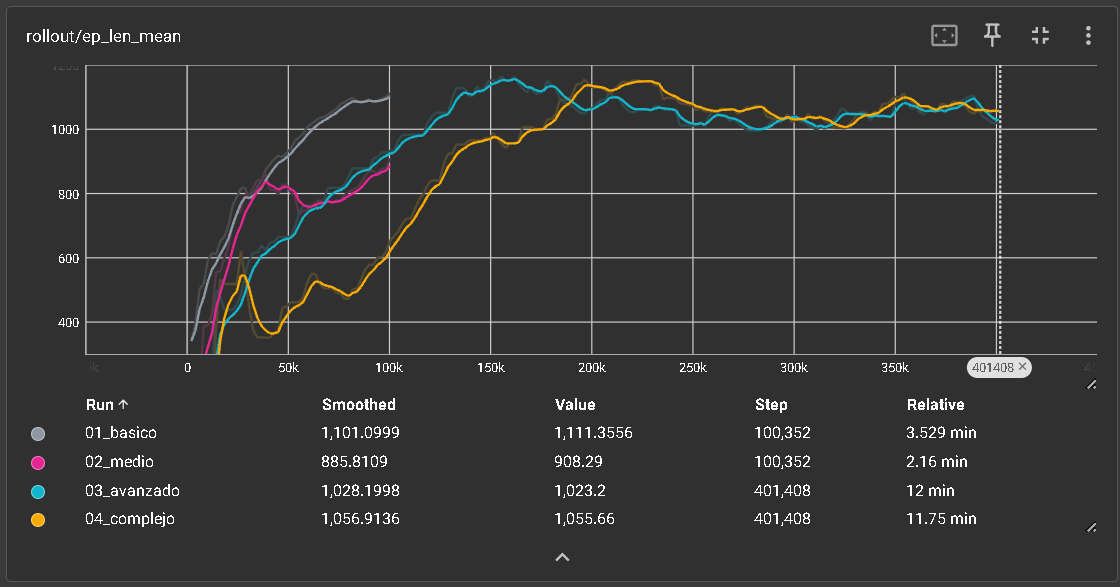

La duración promedio de cada episodio aumenta a medida que aumentan los pasos de entrenamiento.

- Para los agentes que fueron entrenados solo con 100k pasos, se ve que depende que hay una diferencia notable y una divergencia alrededor del paso 40k, esto se asocia con la calidad de la red, ya que como su pudo ver el agente 'medio' es el que peor rendimiento tuvo, y se ve reflejado en el gráfico.
- Por otro lado las curvas para los agentes 'avanzado' y 'complejo', convergen alrededor del paso 200k, y se estabilizan alrededor de 1.100, terminando el entrenamiento con valores cercanos a ese numero.

#### ep_rew_mean

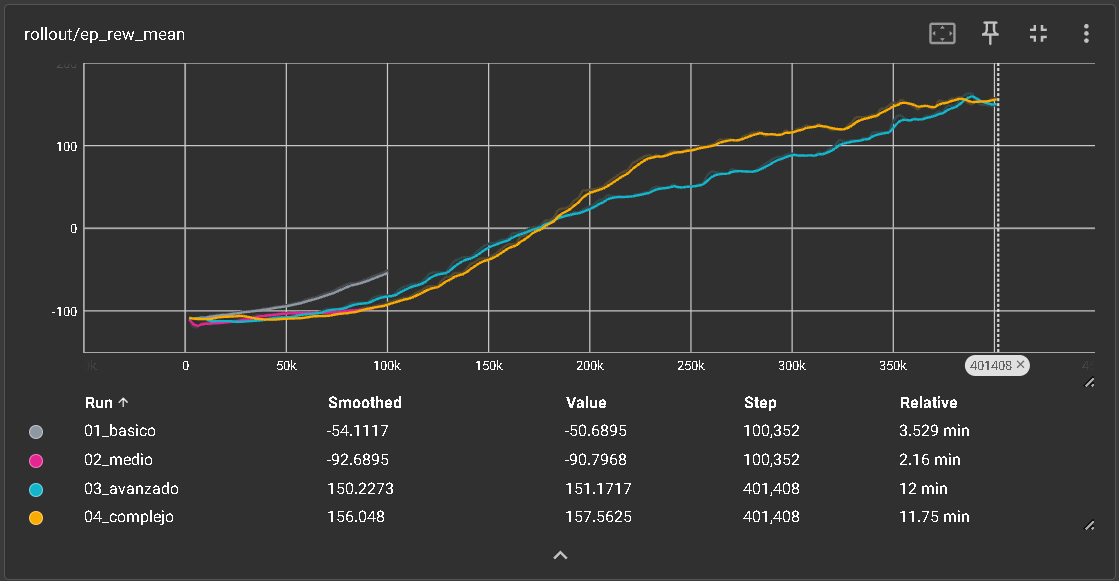

Se observa a medida que aumentan los pasos, la recompensa promedio va aumentando.

- Para todos los agentes el entrenamiento es bastante lento y no progresa mucho entre 0 y 100k pasos.
- Donde los agentes más aprenden es entre 100k y 250k, la que como se observa la pendiente aumenta de forma significativa comparado don el periodo anterior.
- Posterior a los 250k pasos la curva modera su pendiente, si bien sigue aprendiendo no lo hace a la misma velocidad que antes.

#### time_fps

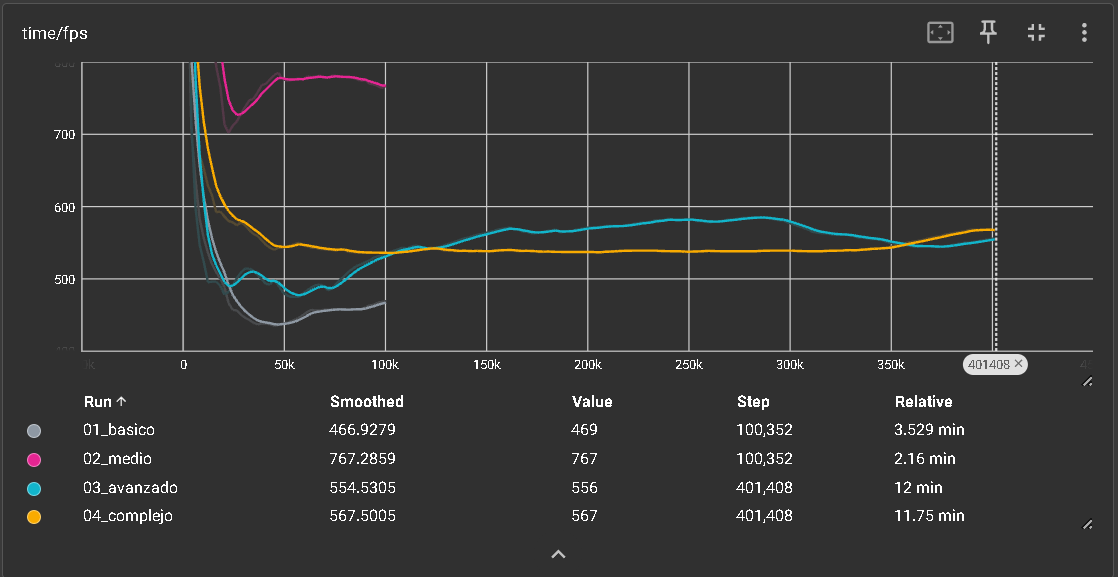

En los primeros 50k pasos se observa que la velocidad de entrenamiento decae fuertemente, esto se debe a que en un principio los episodios son más cortos, a medida que el agente va aprendiendo los episodios van extendiéndose hasta llegar a un punto estable, en el que hay una meseta y un valor estable, alrededor de 550.